# Prueba de estrés de liquidez inversa y las pruebas de validación de liquidez

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los cuadernos 01 a 04 de este tema
- **Tiempo de lectura:** unos 40 minutos

## Objetivos

Al terminar este cuaderno puedes:

- enunciar la prueba de estrés de liquidez inversa como una pregunta ("¿cuánto más rápido deben salir los depósitos para que el banco sobreviva solo 30 días?") y responderla con el motor como un multiplicador de las tasas de fuga;
- explicar el tope del multiplicador (ninguna tasa sobre 1), la propiedad de umbral de la solución y las tres razones por las que el motor rechaza una meta;
- leer las pruebas de validación del paquete de liquidez: el viaje de ida y vuelta del solucionador, la monotonía del período de supervivencia y la identidad de la NLP;
- comparar cada resultado con el documento versionado, nombrando la versión del motor que lo calculó.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Tres documentos versionados del caso C16 (agregados reales del reporte de llamada de la FDIC del banco que quebró el 2023-03-10 hasta el 2022-12-31, comportamiento y depósitos sintéticos, clase de licencia `mirror-allowed`):

- `data/derived/C16/reverse-stress.json`: la tensión inversa de tres bases (LiST Adverso, LiST Extremo y la corrida rápida) con una meta de 30 días: el tope, la curva del período de supervivencia frente al multiplicador, el multiplicador resuelto con su viaje de ida y vuelta y las filas de prueba.
- `data/derived/C16/list-adverse.json` y `data/derived/C16/list-extreme.json`: las escaleras (segmentos, series diarias) con las que se reconstruyen los escenarios de las dos bases LiST, como en el cuaderno 04.

La pregunta viene de la escalera de modelos de liquidez de la investigación (tensión de liquidez inversa, peldaño 5 de la escalera: el multiplicador de fuga con el que el período de supervivencia cae bajo una meta, por ejemplo 30 días), y de la práctica supervisora de someter a tensión en muchos escenarios, cortos y prolongados, individualmente y en combinación (BCBS, 2008, Principio 10). Los montos están en miles de USD.

In [2]:
# Cargar los tres documentos versionados (el cuaderno está tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
documents = {}
for name in ("reverse-stress", "list-adverse", "list-extreme"):
    documents[name] = json.loads((ROOT / "data" / "derived" / "C16" / f"{name}.json").read_text(encoding="utf-8"))
    print(name, "| calculado con riskvalidation", documents[name]["provenance"]["riskvalidation_version"], "| instalado", rv.__version__)

reverse_doc = documents["reverse-stress"]
outputs = reverse_doc["outputs"]
bases = {base["base_id"]: base for base in outputs["bases"]}
print("meta del documento (días):", outputs["target"]["days"])
print("el documento pide el multiplicador umbral: el menor con el que el período de supervivencia es a lo sumo la meta")
print("el multiplicador escala la tasa diaria de cada segmento, con cada tasa limitada a 1")

reverse-stress | calculado con riskvalidation 0.9.0 | instalado 0.9.0
list-adverse | calculado con riskvalidation 0.9.0 | instalado 0.9.0
list-extreme | calculado con riskvalidation 0.9.0 | instalado 0.9.0
meta del documento (días): 30
el documento pide el multiplicador umbral: el menor con el que el período de supervivencia es a lo sumo la meta
el multiplicador escala la tasa diaria de cada segmento, con cada tasa limitada a 1


## Método

### Paso 1: el escenario y un CBC que el motor pueda usar

La tensión inversa toma un escenario base (segmentos con una clase y un saldo inicial, cuaderno 04) y un CBC diario. El solucionador del motor calcula la NLP a partir del CBC y de las salidas conductuales de los segmentos, y no toma entradas ni salidas contractuales. La escalera del documento sí las tiene, así que el documento le entrega al solucionador un **CBC efectivo** que absorbe ambas y deja intacta la NLP de la escalera:

$$\mathrm{CBC}^{\mathrm{eff}}(t) = \mathrm{CBC}(t) + \sum_{s \le t} I(s) - \sum_{s \le t} O_{\text{contractual}}(s), \qquad \mathrm{NLP}(t) = \mathrm{CBC}^{\mathrm{eff}}(t) - \sum_{s \le t} O_{\text{segments}}(s)$$

Esta es una convención del documento del producto (el motor no la impone), y la identidad es verificable: la celda siguiente compone los escenarios Adverso y Extremo a partir de los segmentos versionados, construye el CBC efectivo y muestra que la NLP del motor a partir de él es igual a la NLP versionada de la escalera. También corre la prueba `liq.nlp_identity`, cuyo estadístico es el mayor residuo absoluto de la identidad.

In [3]:
# Componer las dos bases LiST, construir la CBC efectiva y verificar que la NLP del motor es la versionada
from riskvalidation.liquidity.ladder import net_liquidity_position
from riskvalidation.liquidity.scenarios import compose_scenario, list_scenario
from riskvalidation.validation.liquidity import nlp_identity

conventions = outputs["conventions"]
rows = {row["variant"]: row for row in conventions["variant_scenarios"]["rows"]}
built = {}
for base_id, severity in (("list-adverse", "adverse"), ("list-extreme", "extreme")):
    lad = documents[base_id]["outputs"]["path"]["ladder"]
    row = rows[base_id]
    segments = {s["segment"]: (s["list_class"], s["opening_balance"]) for s in lad["segments"]}
    scenario = compose_scenario(row["scenario_family"], row["phase"], list_scenario(severity), segments, row["horizon_days"])
    segment_outflows = scenario.outflows().sum(axis=0)
    contractual = np.array(lad["total_outflows"]) - segment_outflows
    effective_cbc = np.array(lad["cbc_total"]) + np.cumsum(lad["total_inflows"]) - np.cumsum(contractual)
    nlp = net_liquidity_position(effective_cbc, segment_outflows, np.zeros_like(segment_outflows))
    identity = nlp_identity(effective_cbc, segment_outflows, np.zeros_like(segment_outflows), np.array(lad["nlp"]))
    built[base_id] = (scenario, effective_cbc)
    print(base_id, "| misma NLP que la escalera:", ("sí" if np.allclose(nlp, lad["nlp"]) else "no"), "| prueba de identidad, mayor residuo:", round(identity.statistic, 9), identity.light.value)

list-adverse | misma NLP que la escalera: sí | prueba de identidad, mayor residuo: 7e-09 green
list-extreme | misma NLP que la escalera: sí | prueba de identidad, mayor residuo: 3e-08 green


### Paso 2: el multiplicador, su tope y la curva del período de supervivencia

Un multiplicador $m \ge 1$ escala la tasa diaria de cada segmento, con la tasa limitada a 1 como máximo (una tasa no puede ser más que todo el stock):

$$q_s'(d) = \min\bigl(m\, q_s(d),\; 1\bigr), \qquad m_{\max} = \frac{1}{\max\{\, q_s(d) : q_s(d) < 1 \,\}}$$

El tope $m_{\max}$ es el multiplicador con el que la mayor tasa bajo 1 llega a 1; más allá, escalar ya no cambia el segmento que importa, así que un punto más allá del tope se rechaza. Una tasa que ya está en 1 (el segmento financiero) se mantiene en 1. El período de supervivencia $\mathrm{SP}(m)$ es no creciente en $m$, y "sobrevive el horizonte" cuenta como más largo que cualquier día. `max_multiplier` da el tope y `survival_vs_multiplier` da el período de supervivencia bajo cada multiplicador de una grilla; la grilla del documento es una convención declarada (1, 1,25, 1,5, 2, 3, 5, 8, 13, 21, 34, 55, 89, 144). La celda siguiente calcula ambas bases y compara con las curvas versionadas.

In [4]:
# El tope y el período de supervivencia bajo cada multiplicador de la grilla, para las dos bases LiST
from riskvalidation.liquidity.reverse import max_multiplier, survival_vs_multiplier

grid_all = conventions["runoff_multiplier_grid"]["values"]
curves = {}
for base_id, (scenario, effective_cbc) in built.items():
    cap = max_multiplier(scenario)
    grid = np.array([m for m in grid_all if m <= cap])
    results = survival_vs_multiplier(scenario, effective_cbc, grid)
    days = [None if r.survives else r.day for r in results]
    committed_days = [point["survival"]["day"] for point in bases[base_id]["curve"]]
    curves[base_id] = (grid, days)
    print(base_id, "| tope:", round(cap, 6), "| tope versionado:", bases[base_id]["max_multiplier"])
    print("   multiplicadores:", [float(m) for m in grid])
    print("   días de supervivencia:", days, "| igual que el documento:", ("sí" if days == committed_days else "no"))
    print("   no creciente:", ("sí" if all(a >= b for a, b in zip(days, days[1:])) else "no"))

list-adverse | tope: 145.234634 | tope versionado: 145.234634
   multiplicadores: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0, 144.0]
   días de supervivencia: [62, 50, 42, 32, 22, 13, 9, 5, 1, 1, 1, 1, 1] | igual que el documento: sí
   no creciente: sí
list-extreme | tope: 93.876528 | tope versionado: 93.876528
   multiplicadores: [1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 8.0, 13.0, 21.0, 34.0, 55.0, 89.0]
   días de supervivencia: [41, 34, 28, 21, 15, 9, 6, 4, 1, 1, 1, 1] | igual que el documento: sí
   no creciente: sí


### Paso 3: resolver el multiplicador umbral

El período de supervivencia alcanza una meta de $T$ días cuando la NLP es negativa algún día hasta $T$: $\mathrm{SP}(m) \le T \iff \min_{t \le T} \mathrm{NLP}(t; m) < 0$. Ese mínimo es una función continua y no creciente de $m$, así que la raíz queda acotada entre $m = 1$ y el tope y se encuentra con el método de Brent (`scipy.optimize.brentq`). El período de supervivencia es un día entero, así que la respuesta es el **multiplicador umbral** $m^*$: el menor $m$, redondeado hacia arriba a seis decimales y nunca sobre el tope, con el que $\mathrm{SP}(m) \le T$.

$$m^* = \min\{\, m \in [1, m_{\max}] : \mathrm{SP}(m) \le T \,\}, \qquad \mathrm{SP}(m^*) \le T < \mathrm{SP}(m^* - 10^{-6})$$

La segunda desigualdad es el viaje de ida y vuelta: la solución alcanza la meta, y un poco por debajo de ella la meta aún no se alcanza. `solve_multiplier` devuelve el multiplicador, el período de supervivencia en él y el período de supervivencia justo por debajo. La prueba `liq.reverse_stress_round_trip` verifica exactamente esa propiedad. La celda siguiente resuelve para la meta del documento (30 días) en ambas bases, corre la prueba y compara con la solución versionada y las filas de prueba versionadas.

In [5]:
# Resolver el multiplicador umbral en la meta del documento y probar el viaje de ida y vuelta
from riskvalidation.liquidity.reverse import solve_multiplier
from riskvalidation.validation.liquidity import reverse_stress_round_trip

target = outputs["target"]["days"]
status_words = {"solved": "resuelta", "refused": "rechazada"}
committed_rows = {(row["test_id"], row["segment"]): row for row in reverse_doc["tests"]}
solutions = {}
for base_id, (scenario, effective_cbc) in built.items():
    solution = solve_multiplier(scenario, effective_cbc, target)
    solutions[base_id] = solution
    below = solution.survival_just_below
    test = reverse_stress_round_trip(solution.multiplier, solution.survival_at_multiplier, target, 0.0, survival_just_below=below)
    committed = bases[base_id]["solved"]
    row = committed_rows[("liq.reverse_stress_round_trip", base_id)]
    print(base_id, "| estado:", status_words[solution.status], "| m* =", solution.multiplier, "| versionado:", committed["multiplier"])
    print("   supervivencia en m*:", solution.survival_at_multiplier, "| justo bajo m* (6 decimales):", below.day, "| supervivencia base:", bases[base_id]["base_survival"]["day"])
    print("   prueba de ida y vuelta:", test.statistic, test.light.value, "| fila versionada:", row["statistic"], row["light"], "| calculada con", reverse_doc["provenance"]["riskvalidation_version"])

list-adverse | estado: resuelta | m* = 2.118175 | versionado: 2.118175
   supervivencia en m*: 30 | justo bajo m* (6 decimales): 31 | supervivencia base: 62
   prueba de ida y vuelta: 0.0 green | fila versionada: 0.0 green | calculada con 0.9.0
list-extreme | estado: resuelta | m* = 1.383141 | versionado: 1.383141
   supervivencia en m*: 30 | justo bajo m* (6 decimales): 31 | supervivencia base: 41
   prueba de ida y vuelta: 0.0 green | fila versionada: 0.0 green | calculada con 0.9.0


### Paso 4: cuando el motor rechaza

Una meta que no queda acotada se rechaza con su razón, nunca se responde con un número. Hay tres razones: la meta no es menor que el horizonte (un período de supervivencia bajo ella no se distingue de sobrevivir el horizonte); el período de supervivencia base ya es menor o igual que la meta (no hay nada que invertir); o ningún multiplicador bajo el tope alcanza la meta. En este caso solo surgen las dos primeras: toda base llega al día 1 bajo su tope (las curvas del paso 2 terminan en 1). La base de corrida rápida del documento se rechaza por la primera razón: su horizonte es de 5 días y la meta es 30. La celda siguiente le pide al motor seis metas sobre la base Adversa (una exploración, no filas versionadas) y clasifica cada respuesta, y luego imprime el rechazo versionado de la corrida rápida en el idioma del cuaderno.

In [6]:
# Seis metas sobre la base Adverso: el motor responde con un multiplicador o rechaza con una de las tres razones
scenario, effective_cbc = built["list-adverse"]
kinds = {"horizon": "no es menor que el horizonte", "base": "la supervivencia base ya es menor o igual que la meta", "cap": "ningún multiplicador bajo el tope la alcanza"}
for days in (5, 31, 62, 124, 125, 200):
    answer = solve_multiplier(scenario, effective_cbc, days)
    if answer.status == "solved":
        print(f"meta {days:4d} | resuelta | m* = {'ninguno' if answer.multiplier is None else answer.multiplier}")
    else:
        kind = "horizon" if "not below the horizon" in answer.reason else "base" if "already at or below" in answer.reason else "cap"
        print(f"meta {days:4d} | rechazada: {kinds[kind]} | m* = {'ninguno' if answer.multiplier is None else answer.multiplier}")

fast_run = bases["fast-run"]
print("corrida rápida, versionada:", status_words[fast_run["solved"]["status"]], "|", fast_run["solved"]["refusal_reason"]["es"])
print("fila de prueba de la corrida rápida:", committed_rows[("liq.reverse_stress_round_trip", "fast-run")]["light"])

meta    5 | resuelta | m* = 12.65873
meta   31 | resuelta | m* = 2.047593
meta   62 | rechazada: la supervivencia base ya es menor o igual que la meta | m* = ninguno
meta  124 | rechazada: la supervivencia base ya es menor o igual que la meta | m* = ninguno
meta  125 | rechazada: no es menor que el horizonte | m* = ninguno
meta  200 | rechazada: no es menor que el horizonte | m* = ninguno
corrida rápida, versionada: rechazada | El objetivo de 30 días no es menor que el horizonte de 5 días: no existe un intervalo.
fila de prueba de la corrida rápida: not_evaluated


### Paso 5: monotonía del período de supervivencia

El período de supervivencia no debe alargarse cuando el escenario se vuelve más severo (BCE, 2019, y el dosier de investigación). La prueba `liq.survival_monotone_in_severity` toma una lista de períodos de supervivencia ordenados del escenario más suave al más severo (con "sobrevive el horizonte" contado como más largo que cualquier día) y devuelve el mayor alargamiento a lo largo del orden, en días: verde si es cero. El documento la corre a lo largo de la curva de cada base. La celda siguiente la corre sobre las curvas del paso 2, entre las dos severidades de LiST (Adverso y luego Extremo), y sobre una violación plantada (el orden inverso) para mostrar cómo se ve un rojo.

In [7]:
# La prueba de monotonía a lo largo de cada curva, entre las dos severidades, y sobre una violación plantada
from riskvalidation.validation.liquidity import survival_monotone_in_severity

for base_id, (grid, days) in curves.items():
    along = survival_monotone_in_severity(days)
    row = committed_rows[("liq.survival_monotone_in_severity", base_id)]
    print(base_id, "| a lo largo de la curva: mayor alargamiento (días):", along.statistic, along.light.value, "| fila versionada:", row["light"])

base_survival = [bases["list-adverse"]["base_survival"]["day"], bases["list-extreme"]["base_survival"]["day"]]
across = survival_monotone_in_severity(base_survival)
planted = survival_monotone_in_severity(base_survival[::-1])
print("entre severidades (Adverso, Extremo):", base_survival, "|", across.statistic, across.light.value)
print("violación plantada (Extremo, Adverso):", base_survival[::-1], "|", planted.statistic, planted.light.value)

list-adverse | a lo largo de la curva: mayor alargamiento (días): 0.0 green | fila versionada: green
list-extreme | a lo largo de la curva: mayor alargamiento (días): 0.0 green | fila versionada: green
entre severidades (Adverso, Extremo): [62, 41] | 0.0 green
violación plantada (Extremo, Adverso): [41, 62] | 21.0 red


### Paso 6: el diagnóstico del acantilado

El último test del paquete que presentó el cuaderno 01 es el efecto acantilado entre el día 30 y el día 35 como proporción de los activos totales, $(\mathrm{NLP}(35) - \mathrm{NLP}(30)) / \mathrm{TA}$. `liq.cliff_effect_diagnostic` lo califica con dos convenciones del producto (ámbar bajo -0,01, rojo bajo -0,03), porque la nota del BCE no define ningún límite; es un diagnóstico de la forma de la posición, no un umbral regulatorio. La celda siguiente llama a la prueba sobre la serie NLP versionada de ambas bases y compara con las filas versionadas.

In [8]:
# El diagnóstico del acantilado sobre la serie de NLP versionada de las dos bases LiST, contra las filas versionadas
from riskvalidation.validation.liquidity import cliff_effect_diagnostic

for base_id in ("list-adverse", "list-extreme"):
    document = documents[base_id]
    nlp = np.array(document["outputs"]["path"]["ladder"]["nlp"])
    diagnostic = cliff_effect_diagnostic(nlp, document["outputs"]["balance_sheet"]["total_assets"])
    committed = next(row for row in document["tests"] if row["test_id"] == "liq.cliff_effect_diagnostic")
    print(base_id, "| efecto acantilado:", round(diagnostic.statistic, 6), "| cambio de la NLP (miles de millones de USD):", round(diagnostic.metric / 1e6, 3), "| semáforo:", diagnostic.light.value)
    print("   fila versionada:", round(committed["statistic"], 6), committed["light"], "| mismo estadístico:", ("sí" if np.isclose(diagnostic.statistic, committed["statistic"]) else "no"))

list-adverse | efecto acantilado: -0.022246 | cambio de la NLP (miles de millones de USD): -4.65 | semáforo: amber
   fila versionada: -0.022246 amber | mismo estadístico: sí
list-extreme | efecto acantilado: -0.029776 | cambio de la NLP (miles de millones de USD): -6.224 | semáforo: amber
   fila versionada: -0.029776 amber | mismo estadístico: sí


La última celda dibuja la respuesta que da la tensión inversa. Las curvas escalonadas son el período de supervivencia frente al multiplicador de las tasas de fuga para ambas bases, con la meta de 30 días como línea horizontal y los multiplicadores umbral como marcas verticales.

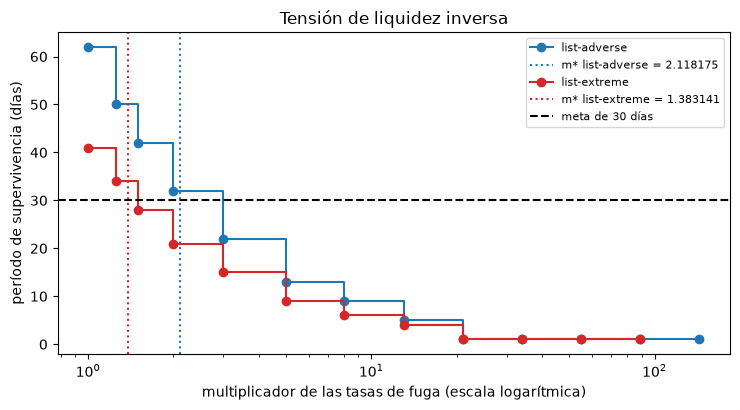

In [9]:
# Dibujar el período de supervivencia contra el multiplicador de las tasas de salida, con la meta y los multiplicadores umbral
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for (base_id, (grid, days)), color in zip(curves.items(), ("tab:blue", "tab:red")):
    ax.step(grid, days, where="post", marker="o", color=color, label=base_id)
    ax.axvline(solutions[base_id].multiplier, color=color, linestyle=":", label=f"m* {base_id} = {solutions[base_id].multiplier}")
ax.axhline(target, color="black", linestyle="--", label="meta de 30 días")
ax.set_xscale("log")
ax.set_xlabel("multiplicador de las tasas de fuga (escala logarítmica)")
ax.set_ylabel("período de supervivencia (días)")
ax.set_title("Tensión de liquidez inversa")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **CBC efectivo.** Con el CBC efectivo la NLP del motor es igual a la NLP versionada de ambas escaleras, y la prueba de identidad encuentra un mayor residuo de 7e-09 (Adverso) y 3e-08 (Extremo), verde.
- **Tope y curvas.** El tope es 145,234634 para Adverso y 93,876528 para Extremo. Bajo Adverso el período de supervivencia va de 62 días con $m = 1$ a 32 con 2, 5 con 13 y 1 desde 21; bajo Extremo de 41 a 21 con 2, 4 con 13 y 1 desde 21. Ambas curvas son no crecientes e iguales a las versionadas.
- **Los multiplicadores umbral.** Para sobrevivir solo 30 días las tasas de fuga deben ser 2,118175 veces más rápidas bajo Adverso y 1,383141 veces más rápidas bajo Extremo; el período de supervivencia con esos multiplicadores es 30 y un pelo por debajo es 31, así que son umbrales. El viaje de ida y vuelta es verde con estadístico 0,0, como en las filas versionadas. La distancia a la meta es corta: duplicar las tasas Adversas ya lleva al banco de 62 a 32 días.
- **Rechazos.** Para metas de 5 y 31 días la base Adversa da multiplicadores de 12,65873 y 2,047593. Una meta de 62 o 124 días se rechaza porque el período de supervivencia base (62 días) ya es menor o igual a ella; una meta de 125 o 200 días se rechaza porque no es menor que el horizonte. La base de corrida rápida versionada se rechaza por esta última razón (una meta de 30 días frente a un horizonte de 5), y su fila de ida y vuelta es `not_evaluated`: no se inventa ningún número.
- **Monotonía.** A lo largo de cada curva el mayor alargamiento del período de supervivencia es 0,0 días, verde, como en las filas versionadas; entre las dos severidades ([62, 41]) es 0,0 y verde. El orden inverso plantado ([41, 62]) se alarga 21,0 días y es rojo, lo que muestra que la prueba puede fallar.
- **El diagnóstico del acantilado.** El efecto acantilado es -0,022246 en la base Adversa y -0,029776 en la base Extrema; ambos son ámbar bajo las dos convenciones del producto e iguales a las filas versionadas. La base Extrema queda justo sobre la línea roja de -0,03.

Lo que este cuaderno no muestra: si un multiplicador así es plausible frente a lo ocurrido en 2023 (esa es la pregunta de los cuadernos 07 y 08), ni cómo cambiaría el multiplicador con otro calendario de CBC. Los multiplicadores son propiedades del comportamiento sintético del caso.

## Resumen

- La tensión inversa invierte la pregunta de un escenario: en vez de "¿cuánto sobrevive el banco con esta fuga?", "¿cuánto más rápida debe ser la fuga para que el banco dure solo una meta?".
- La respuesta es un multiplicador de las tasas diarias, limitado para que ninguna tasa pase de 1, y es un umbral: la meta se alcanza en él y no justo por debajo.
- El motor rechaza una meta con su razón en vez de devolver un número que no puede sustentar.
- Las pruebas del paquete verifican la identidad de la NLP, el viaje de ida y vuelta del solucionador y la monotonía del período de supervivencia, y cada una está versionada con la versión del motor que la calculó.

**Qué probar a continuación.** Cambia la meta del paso 4 a 45 y 90 días y mira cómo se mueve el multiplicador; luego sigue con el cuaderno 07.

## Referencias

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), Table 3.3 (the run-off rates of the bases). https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- BCBS (2008), Principles for sound liquidity risk management and supervision, Principle 10 (stress tests in short-term and protracted, institution-specific and market-wide scenarios). https://www.bis.org/publ/bcbs144.htm